#  Colombo Tea Auction Prices
**CM4371 Machine Learning & Pattern Recognition: Hands-on Project**

**Goal:** Predict Colombo tea auction prices (Rs/kg) using **Bagging, Boosting and Stacking**, compare **Random Forest vs XGBoost**, and build **hybrid models** (RF + ARIMA, RF + ANN).


**Dataset:** `hesandism/colombo-tea-auction-prices` (Hugging Face), a Sri Lankan dataset with real auction records, USD/LKR exchange rate and weather severity.

**Pipeline:** Load, EDA, features, time-based split, ensembles, RF vs XGB, hybrids, dashboard.

In [21]:
import warnings, time, json, re, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import TimeSeriesSplit, KFold, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor, VotingRegressor)
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
try:
    from catboost import CatBoostRegressor
    HAS_CAT = True
except Exception:
    HAS_CAT = False
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")
RANDOM = 42
print("CatBoost available:", HAS_CAT)

CatBoost available: True


## 1. Load data

In [22]:
CSV_PATH = "colombo_tea_auction.csv"   # created by download_dataset.py
df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df.dtypes)
df.head()

(12233, 26)
sale_id                              str
catalogue                            str
category                             str
elevation                            str
segment                              str
grade                                str
tier                                 str
price_mid_lkr                    float64
region                               str
text_crop_change                     str
text_keywords                        str
temperature_2m_mean_mean         float64
precipitation_sum_total_lag1     float64
sunshine_duration_total_lag1     float64
temperature_2m_mean_mean_lag1    float64
precipitation_sum_total_lag2     float64
sunshine_duration_total_lag2     float64
temperature_2m_mean_mean_lag2    float64
precipitation_sum_total_lag3     float64
sunshine_duration_total_lag3     float64
temperature_2m_mean_mean_lag3    float64
sale_number                        int64
sale_year                        float64
sale_date_raw                        str
avg_

,sale_id,catalogue,category,elevation,segment,grade,tier,price_mid_lkr,region,text_crop_change,...,sunshine_duration_total_lag2,temperature_2m_mean_mean_lag2,precipitation_sum_total_lag3,sunshine_duration_total_lag3,temperature_2m_mean_mean_lag3,sale_number,sale_year,sale_date_raw,avg_weather_severity,fx_usd
0,SALE_2023_42,low_grown,bop,low_grown,unknown,bop,select_best,1750.0,low_grown,decrease,...,140305.23,25.09,169.6,138530.06,24.86,42,2023.0,24TH/25TH October 2023,3.0,320.81
1,SALE_2023_42,low_grown,bop,low_grown,unknown,bop,best,1325.0,low_grown,decrease,...,140305.23,25.09,169.6,138530.06,24.86,42,2023.0,24TH/25TH October 2023,3.0,320.81
2,SALE_2023_42,low_grown,bop,low_grown,unknown,bop,below_best,950.0,low_grown,decrease,...,140305.23,25.09,169.6,138530.06,24.86,42,2023.0,24TH/25TH October 2023,3.0,320.81
3,SALE_2023_42,low_grown,bop,low_grown,unknown,bop,others,875.0,low_grown,decrease,...,140305.23,25.09,169.6,138530.06,24.86,42,2023.0,24TH/25TH October 2023,3.0,320.81
4,SALE_2023_42,low_grown,bop1,low_grown,unknown,bop1,select_best,3325.0,low_grown,decrease,...,140305.23,25.09,169.6,138530.06,24.86,42,2023.0,24TH/25TH October 2023,3.0,320.81


## 2. Detect target and date columns
The target is the price column (Rs/kg). If the auto-detection picks the wrong one, set `TARGET_OVERRIDE = "your_column"`.

In [23]:
TARGET_OVERRIDE = None

cands = [c for c in df.columns if "price" in c.lower()]
print("Price-like columns:", cands)
if TARGET_OVERRIDE:
    TARGET = TARGET_OVERRIDE
else:
    pref = [c for c in ["price", "price_lkr", "avg_price", "price_per_kg", "price_lkr_per_kg"] if c in df.columns]
    lkr = [c for c in cands if "lkr" in c.lower()]
    TARGET = (pref or lkr or cands)[0]
print("TARGET =", TARGET)

def build_date(d):
    for c in ["sale_date", "date", "auction_date"]:
        if c in d.columns:
            x = pd.to_datetime(d[c], errors="coerce")
            if x.notna().mean() > 0.9:
                return x
    if "sale_date_raw" in d.columns:           # e.g. "24TH/25TH October 2023"
        s = d["sale_date_raw"].astype(str)
        day = s.str.extract(r"(\d{1,2})")[0]
        mon = s.str.extract(r"([A-Za-z]{3,9})\s+\d{4}")[0]
        yr = s.str.extract(r"(\d{4})")[0]
        x = pd.to_datetime(day + " " + mon + " " + yr, errors="coerce")
        if x.notna().mean() > 0.9:
            return x
    m = d["sale_id"].str.extract(r"(\d{4})_(\d+)")   # SALE_2023_42 -> year + weekly sale number
    return pd.to_datetime(m[0] + "-01-01") + pd.to_timedelta((m[1].astype(int) - 1) * 7, unit="D")

df["date"] = build_date(df)
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
before = len(df)
df = df.dropna(subset=[TARGET, "date"])
df = df[df[TARGET] > 0].reset_index(drop=True)
print(f"Rows kept: {len(df)} / {before}")
print("Date range:", df.date.min().date(), "->", df.date.max().date())
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
df[[TARGET, "date"]].describe()

Price-like columns: ['price_mid_lkr']
TARGET = price_mid_lkr
Rows kept: 11797 / 12233
Date range: 2023-10-24 -> 2026-03-24
Missing values:
 Series([], dtype: int64)


,price_mid_lkr,date
count,11797.000000,11797
mean,1274.037806,2024-12-31 18:02:50.280579
min,520.000000,2023-10-24 00:00:00
25%,920.000000,2024-05-14 00:00:00
50%,1110.000000,2024-11-11 00:00:00
75%,1425.000000,2025-09-09 00:00:00
max,6750.000000,2026-03-24 00:00:00
std,642.607484,NaN


## 3. Exploratory Data Analysis

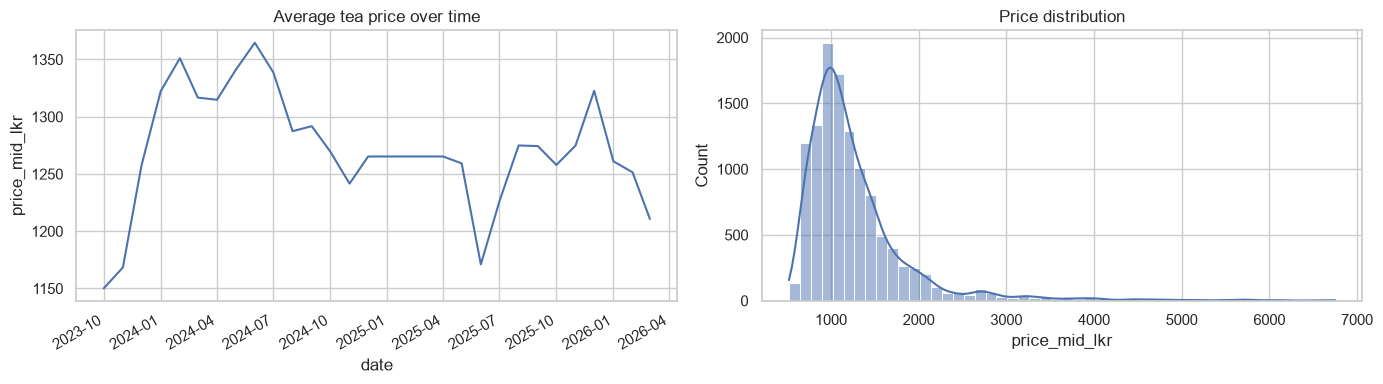

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly = df.groupby(df.date.dt.to_period("M"))[TARGET].mean()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=ax[0]); ax[0].set_title("Average tea price over time"); ax[0].set_ylabel(TARGET)
sns.histplot(df[TARGET], bins=50, ax=ax[1], kde=True); ax[1].set_title("Price distribution")
plt.tight_layout(); plt.show()

**Interpretation:** *(edit after seeing the plot: overall trend, spikes, e.g. 2022 economic crisis, and skew of the price distribution.)*

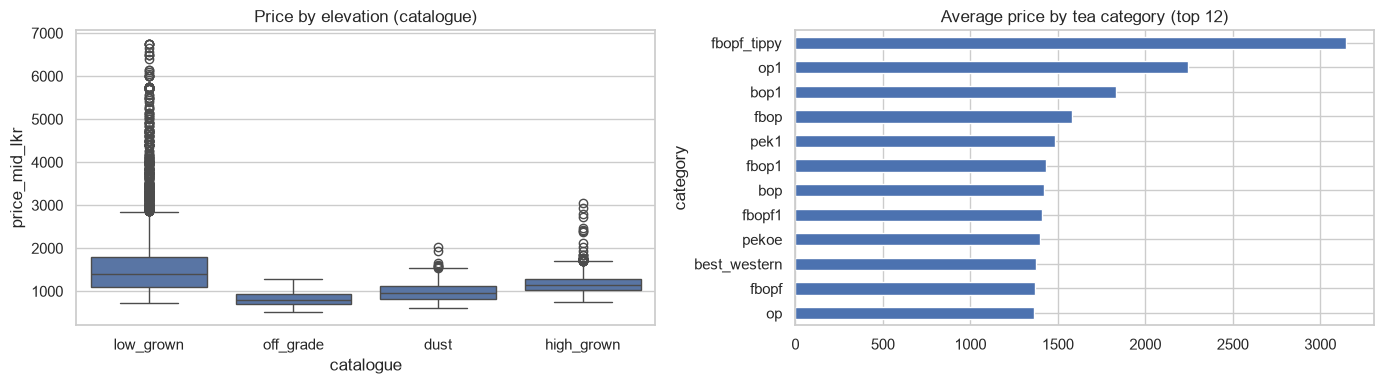

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
if "catalogue" in df.columns:
    sns.boxplot(data=df, x="catalogue", y=TARGET, ax=ax[0]); ax[0].set_title("Price by elevation (catalogue)")
if "category" in df.columns:
    df.groupby("category")[TARGET].mean().sort_values().tail(12).plot.barh(ax=ax[1])
    ax[1].set_title("Average price by tea category (top 12)")
plt.tight_layout(); plt.show()

**Interpretation:** *(which elevation and grades fetch the highest prices, and why, e.g. high-grown teas are usually more premium.)*

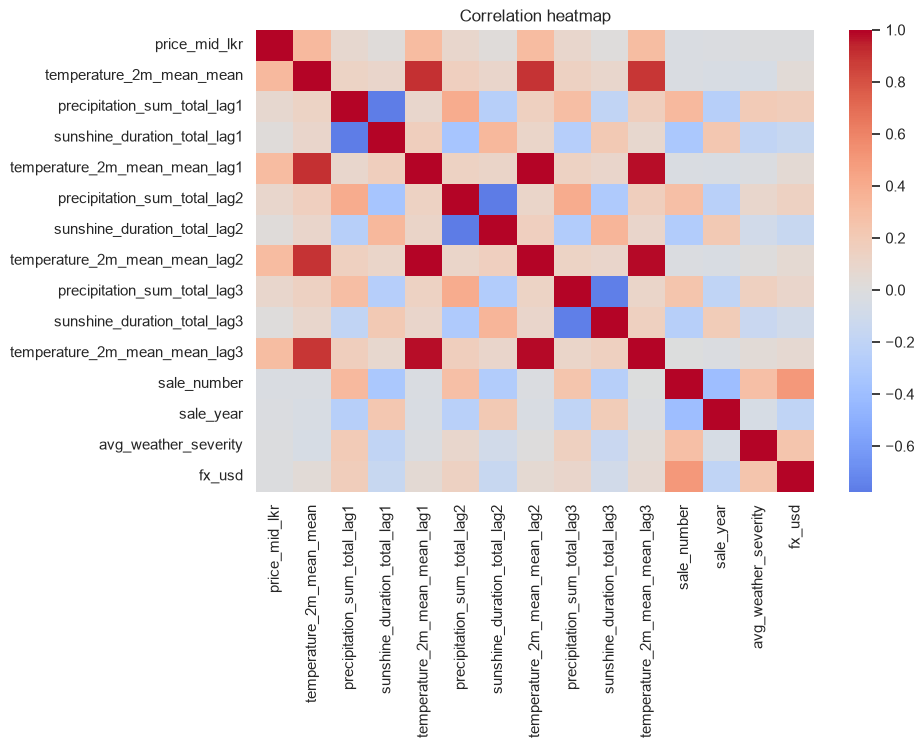

In [26]:
num_eda = df.select_dtypes(include="number").columns.tolist()
plt.figure(figsize=(9, 6))
sns.heatmap(df[num_eda].corr(), annot=len(num_eda) <= 12, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap"); plt.show()

**Interpretation:** *(which numeric variables, e.g. USD/LKR rate or weather, relate most to price.)*

## 4. Feature engineering
- Calendar features: year, month, week
- **Lag features:** the previous sale's average price for the same catalogue and category (`lag1`) and the rolling mean of the last 4 sales (`roll4`)
- One-hot encoding for categorical columns
- Columns that are other price versions (e.g. USD price) are **excluded** to avoid target leakage

In [27]:
df = df.sort_values("date").reset_index(drop=True)
df["year"] = df.date.dt.year
df["month"] = df.date.dt.month
df["week"] = df.date.dt.isocalendar().week.astype(int)

keys = [k for k in ["catalogue", "category"] if k in df.columns]
g = df.groupby(keys + ["date"])[TARGET].mean().reset_index().sort_values(keys + ["date"])
g["lag1"] = g.groupby(keys)[TARGET].shift(1)
g["roll4"] = g.groupby(keys)[TARGET].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
df = df.merge(g[keys + ["date", "lag1", "roll4"]], on=keys + ["date"], how="left")
df = df.dropna(subset=["lag1"]).sort_values("date").reset_index(drop=True)

drop = [TARGET, "date", "sale_id", "sale_date_raw"]
price_like = [c for c in df.columns if "price" in c.lower() and c != TARGET]
bool_cols = df.select_dtypes(include="bool").columns.tolist()
df[bool_cols] = df[bool_cols].astype(str)
cat_cols = [c for c in df.select_dtypes(include=["object", "category"]).columns
            if c not in drop + price_like and df[c].nunique() <= 60]
num_cols = [c for c in df.select_dtypes(include="number").columns
            if c not in drop + price_like and df[c].notna().any()]
feat = num_cols + cat_cols
print("Excluded (leakage):", price_like)
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)
print("Rows:", len(df))

Excluded (leakage): []
Numeric features: ['temperature_2m_mean_mean', 'precipitation_sum_total_lag1', 'sunshine_duration_total_lag1', 'temperature_2m_mean_mean_lag1', 'precipitation_sum_total_lag2', 'sunshine_duration_total_lag2', 'temperature_2m_mean_mean_lag2', 'precipitation_sum_total_lag3', 'sunshine_duration_total_lag3', 'temperature_2m_mean_mean_lag3', 'sale_number', 'sale_year', 'avg_weather_severity', 'fx_usd', 'year', 'month', 'week', 'lag1', 'roll4']
Categorical features: ['catalogue', 'category', 'elevation', 'segment', 'grade', 'tier', 'region', 'text_crop_change', 'text_keywords']
Rows: 11580


## 5. Time-based train/test split
Rows from the same auction are almost identical, so a random split would leak information. I **train on the oldest 80% of sale dates and test on the newest 20%**, which mimics real forecasting.

In [28]:
dates = np.sort(df.date.unique())
cutoff = dates[int(len(dates) * 0.8)]
train, test = df[df.date < cutoff], df[df.date >= cutoff]
print("Cutoff:", pd.Timestamp(cutoff).date(), "| train:", len(train), "| test:", len(test))

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
Xtr = pre.fit_transform(train[feat]); Xte = pre.transform(test[feat])
ytr, yte = train[TARGET].values, test[TARGET].values
feat_names = pre.get_feature_names_out()
print("Feature matrix:", Xtr.shape)

Cutoff: 2025-10-28 | train: 9268 | test: 2312
Feature matrix: (9268, 141)


## 6. Ensemble models: Bagging, Boosting, Stacking
| Family | Models |
|---|---|
| Baseline | Single Decision Tree |
| **Bagging** | BaggingRegressor, Random Forest, Extra Trees |
| **Boosting** | AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost |
| **Stacking** | Voting (average) and Stacking: RF + XGB + LGBM with Ridge as the final model |

In [29]:
results, preds, fitted = [], {}, {}

def evaluate(name, family, model):
    t = time.time(); model.fit(Xtr, ytr); sec = time.time() - t
    p = model.predict(Xte)
    preds[name], fitted[name] = p, model
    results.append(dict(Model=name, Family=family,
                        MAE=mean_absolute_error(yte, p),
                        RMSE=np.sqrt(mean_squared_error(yte, p)),
                        R2=r2_score(yte, p), Train_sec=round(sec, 2)))
    print(f"{name:28s} MAE={results[-1]['MAE']:.2f}  RMSE={results[-1]['RMSE']:.2f}  R2={results[-1]['R2']:.3f}")

evaluate("Decision Tree", "Baseline", DecisionTreeRegressor(max_depth=12, random_state=RANDOM))
evaluate("Bagging (Trees)", "Bagging", BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, n_jobs=-1, random_state=RANDOM))
evaluate("Random Forest", "Bagging", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM))
evaluate("Extra Trees", "Bagging", ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM))
evaluate("AdaBoost", "Boosting", AdaBoostRegressor(DecisionTreeRegressor(max_depth=6), n_estimators=150, learning_rate=0.5, random_state=RANDOM))
evaluate("Gradient Boosting", "Boosting", GradientBoostingRegressor(n_estimators=200, random_state=RANDOM))
evaluate("XGBoost", "Boosting", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, n_jobs=-1, random_state=RANDOM))
evaluate("LightGBM", "Boosting", LGBMRegressor(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=RANDOM))
if HAS_CAT:
    evaluate("CatBoost", "Boosting", CatBoostRegressor(iterations=400, learning_rate=0.05, verbose=0, random_seed=RANDOM, allow_writing_files=False))

base = [("rf", RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=RANDOM)),
        ("xgb", XGBRegressor(n_estimators=250, learning_rate=0.05, n_jobs=-1, random_state=RANDOM)),
        ("lgbm", LGBMRegressor(n_estimators=250, learning_rate=0.05, verbose=-1, random_state=RANDOM))]
evaluate("Voting (average)", "Stacking", VotingRegressor(base))
evaluate("Stacking (RF+XGB+LGBM)", "Stacking", StackingRegressor(base, final_estimator=Ridge(alpha=1.0), cv=KFold(3), n_jobs=1))

Decision Tree                MAE=86.92  RMSE=142.26  R2=0.945
Bagging (Trees)              MAE=68.06  RMSE=111.56  R2=0.966
Random Forest                MAE=68.14  RMSE=112.21  R2=0.965
Extra Trees                  MAE=66.76  RMSE=112.62  R2=0.965
AdaBoost                     MAE=105.70  RMSE=141.02  R2=0.945
Gradient Boosting            MAE=72.11  RMSE=104.46  R2=0.970
XGBoost                      MAE=67.12  RMSE=107.36  R2=0.968
LightGBM                     MAE=67.25  RMSE=101.27  R2=0.972
CatBoost                     MAE=65.71  RMSE=100.87  R2=0.972
Voting (average)             MAE=65.58  RMSE=100.96  R2=0.972
Stacking (RF+XGB+LGBM)       MAE=66.22  RMSE=104.94  R2=0.970


,Model,Family,MAE,RMSE,R2,Train_sec
0,CatBoost,Boosting,65.705,100.874,0.972,4.77
1,Voting (average),Stacking,65.577,100.958,0.972,15.98
2,LightGBM,Boosting,67.246,101.272,0.972,1.49
3,Gradient Boosting,Boosting,72.109,104.465,0.970,21.36
4,Stacking (RF+XGB+LGBM),Stacking,66.220,104.938,0.970,48.28
5,XGBoost,Boosting,67.118,107.360,0.968,4.47
6,Bagging (Trees),Bagging,68.057,111.564,0.966,27.90
7,Random Forest,Bagging,68.137,112.213,0.965,28.88
8,Extra Trees,Bagging,66.761,112.618,0.965,26.20
9,AdaBoost,Boosting,105.698,141.018,0.945,26.53


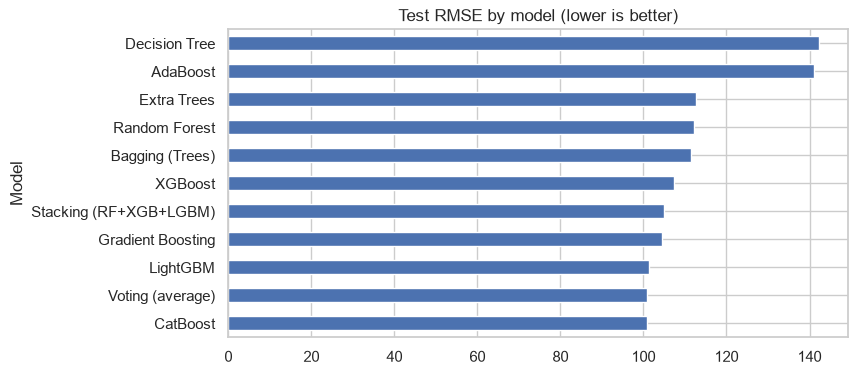

In [30]:
res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(res.round(3))
res.set_index("Model")["RMSE"].sort_values().plot.barh(figsize=(8, 4), title="Test RMSE by model (lower is better)")
plt.show()

**Interpretation:** *(which family won, the gap between the single tree and the ensembles, and whether stacking beat its own base models.)*

## 7. Random Forest vs XGBoost
Light hyperparameter tuning with `RandomizedSearchCV` using a time-aware `TimeSeriesSplit`, then a side-by-side comparison.

In [31]:
tscv = TimeSeriesSplit(3)
rf_s = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM, n_jobs=-1),
    {"n_estimators": [200, 300, 500], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5, 1.0]},
    n_iter=8, cv=tscv, scoring="neg_root_mean_squared_error", random_state=RANDOM).fit(Xtr, ytr)
xgb_s = RandomizedSearchCV(XGBRegressor(random_state=RANDOM, n_jobs=-1),
    {"n_estimators": [200, 400, 600], "max_depth": [3, 5, 7], "learning_rate": [0.02, 0.05, 0.1], "subsample": [0.7, 0.9, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]},
    n_iter=8, cv=tscv, scoring="neg_root_mean_squared_error", random_state=RANDOM).fit(Xtr, ytr)
print("RF best :", rf_s.best_params_)
print("XGB best:", xgb_s.best_params_)
evaluate("Random Forest (tuned)", "Bagging", rf_s.best_estimator_)
evaluate("XGBoost (tuned)", "Boosting", xgb_s.best_estimator_)

RF best : {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
XGB best: {'subsample': 0.9, 'n_estimators': 600, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Random Forest (tuned)        MAE=68.26  RMSE=112.68  R2=0.965
XGBoost (tuned)              MAE=69.63  RMSE=110.94  R2=0.966


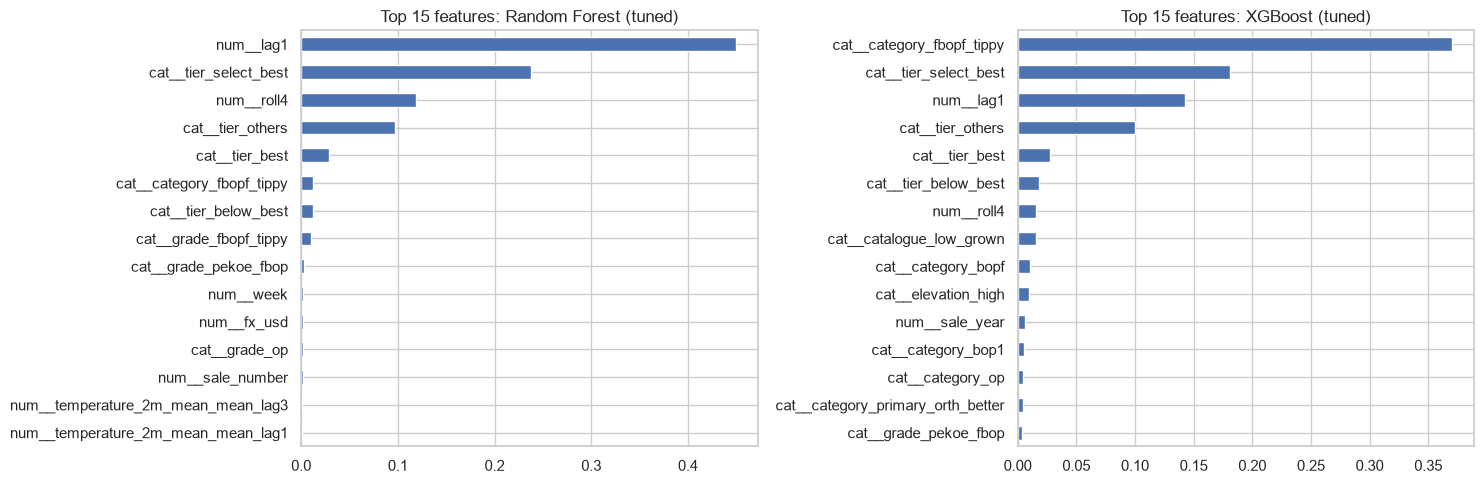

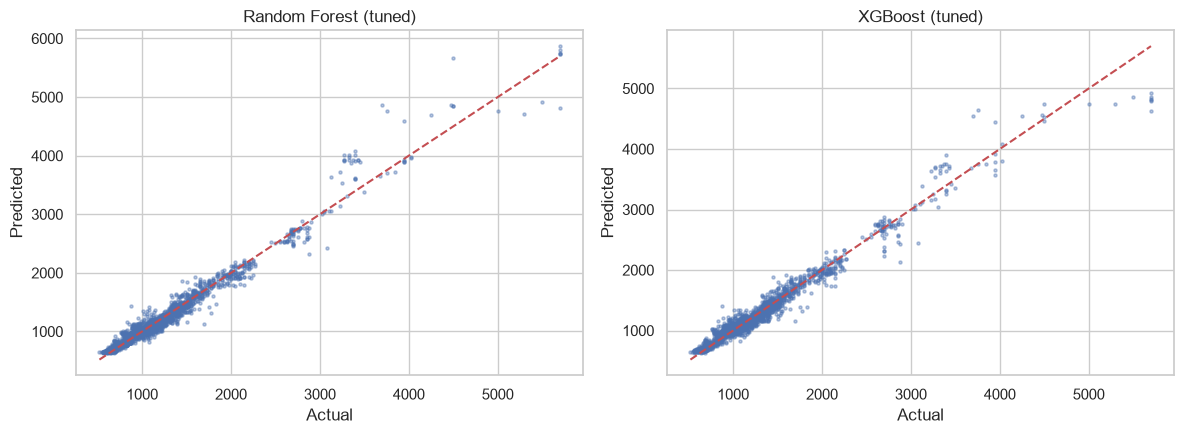

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, (nm, m) in zip(ax, [("Random Forest (tuned)", fitted["Random Forest (tuned)"]), ("XGBoost (tuned)", fitted["XGBoost (tuned)"])]):
    imp = pd.Series(m.feature_importances_, index=feat_names).sort_values().tail(15)
    imp.plot.barh(ax=a, title=f"Top 15 features: {nm}")
plt.tight_layout(); plt.show()

# Predicted vs actual
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, nm in zip(ax, ["Random Forest (tuned)", "XGBoost (tuned)"]):
    a.scatter(yte, preds[nm], s=5, alpha=.4); lim = [yte.min(), yte.max()]
    a.plot(lim, lim, "r--"); a.set_title(nm); a.set_xlabel("Actual"); a.set_ylabel("Predicted")
plt.tight_layout(); plt.show()

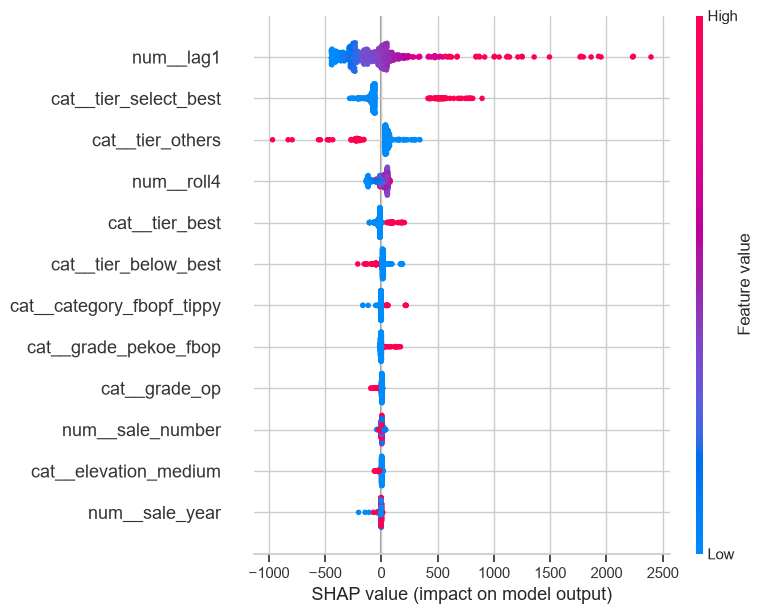

In [33]:
# Optional bonus: SHAP explanation for XGBoost
try:
    import shap
    idx = np.random.RandomState(0).choice(len(Xte), min(500, len(Xte)), replace=False)
    sv = shap.TreeExplainer(fitted["XGBoost (tuned)"]).shap_values(Xte[idx])
    shap.summary_plot(sv, Xte[idx], feature_names=feat_names, max_display=12)
except Exception as e:
    print("SHAP skipped (pip install shap to enable):", e)

### 7.1 Robust comparison: time-aware cross-validation
A single test split can be lucky. `TimeSeriesSplit` (3 folds, always training on the past and validating on the future) gives a fairer comparison.

                 mean     std
Random Forest  0.9552  0.0115
XGBoost        0.9554  0.0087
LightGBM       0.9553  0.0070


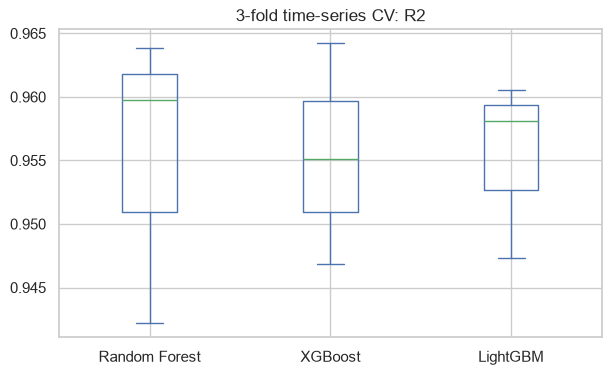

In [34]:
tscv3 = TimeSeriesSplit(3)
cv = {"Random Forest": cross_val_score(fitted["Random Forest (tuned)"], Xtr, ytr, cv=tscv3, scoring="r2", n_jobs=1),
      "XGBoost": cross_val_score(fitted["XGBoost (tuned)"], Xtr, ytr, cv=tscv3, scoring="r2", n_jobs=1),
      "LightGBM": cross_val_score(LGBMRegressor(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=RANDOM), Xtr, ytr, cv=tscv3, scoring="r2", n_jobs=1)}
cvdf = pd.DataFrame(cv)
print(cvdf.agg(["mean", "std"]).T.round(4))
cvdf.plot(kind="box", figsize=(7, 4), title="3-fold time-series CV: R2"); plt.show()

### 7.2 Which features drive the price? (permutation importance)

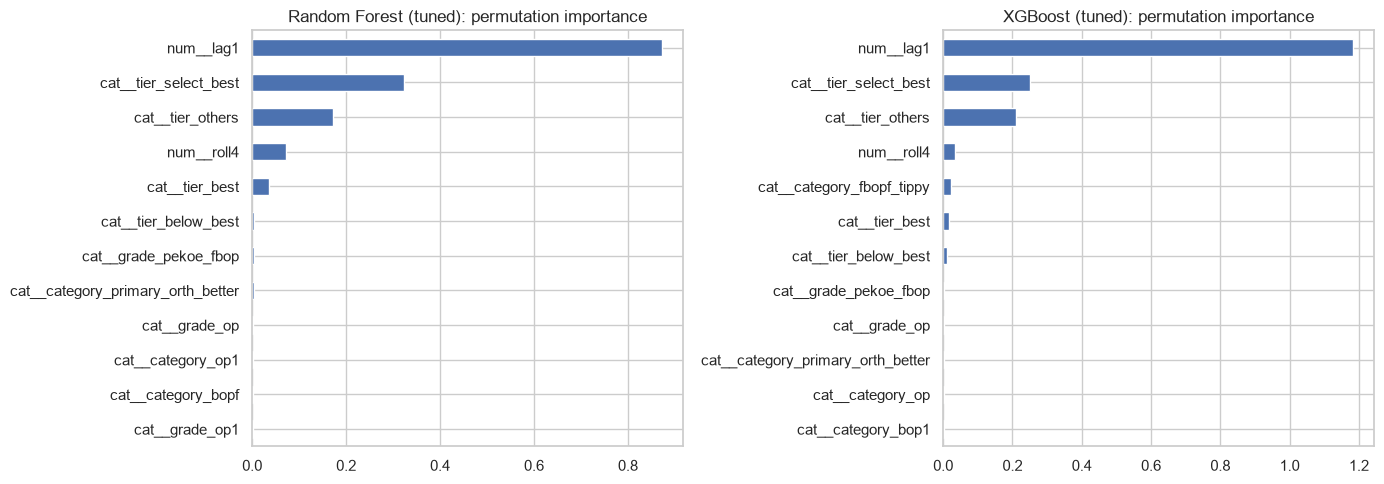

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, n in zip(ax, ["Random Forest (tuned)", "XGBoost (tuned)"]):
    pi = permutation_importance(fitted[n], Xte, yte, n_repeats=3, random_state=RANDOM, n_jobs=1)
    pd.Series(pi.importances_mean, index=feat_names).sort_values().tail(12).plot(kind="barh", ax=a, title=n + ": permutation importance")
plt.tight_layout(); plt.show()

**Why did one win? (write your own conclusion using your numbers)**
- **XGBoost** builds trees *sequentially*, each correcting the previous errors, so it often reaches lower error on structured data and uses lag features well.
- **Random Forest** averages many independent deep trees, which lowers variance, is more robust to noisy prices and needs less tuning.
- Say which one gave the lower RMSE/MAE here, how the training times compare, and which features (lag price, catalogue, category, FX) mattered most.

## 8. Hybrid model 1: RF + ARIMA (time series)
1. Build the **average price per sale date** series.
2. Fit **ARIMA** on the training period (captures trend and autocorrelation) and produce one-step-ahead forecasts for the test period.
3. Train a **Random Forest on the ARIMA residuals** using calendar, FX and weather features.
4. **Hybrid forecast = ARIMA forecast + RF-predicted residual.**

,MAE,RMSE,R2
ARIMA only,22.164,28.142,0.495
RF only (calendar+FX+weather),46.934,52.313,-0.745
Hybrid RF + ARIMA,24.847,32.905,0.309


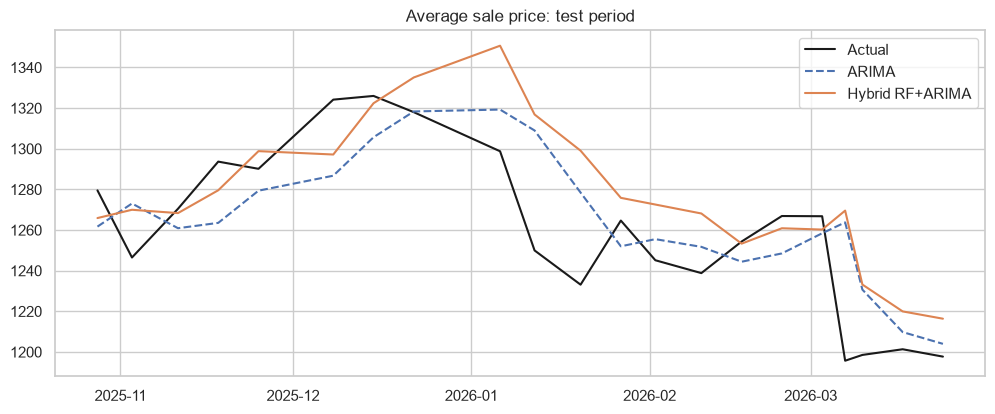

In [36]:
FX = "fx_usd" if "fx_usd" in df.columns else None
WX = "avg_weather_severity" if "avg_weather_severity" in df.columns else None
aggs = {"price": (TARGET, "mean")}
if FX: aggs["fx"] = (FX, "mean")
if WX: aggs["wx"] = (WX, "mean")
ts = df.groupby("date").agg(**aggs).reset_index().sort_values("date")
ts["month"] = ts.date.dt.month; ts["week"] = ts.date.dt.isocalendar().week.astype(int)
tsf = ["month", "week"] + [c for c in ["fx", "wx"] if c in ts.columns]
tr_ts, te_ts = ts[ts.date < cutoff].reset_index(drop=True), ts[ts.date >= cutoff].reset_index(drop=True)

arima = ARIMA(tr_ts.price.values, order=(1, 1, 1)).fit()
full = arima.append(te_ts.price.values, refit=False)
arima_pred = np.asarray(full.predict(start=len(tr_ts), end=len(tr_ts) + len(te_ts) - 1))

resid = np.asarray(arima.resid)[1:]
rf_res = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM, n_jobs=-1)
rf_res.fit(tr_ts[tsf].iloc[1:], resid)
hybrid_pred = arima_pred + rf_res.predict(te_ts[tsf])

rf_only = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM, n_jobs=-1).fit(tr_ts[tsf], tr_ts.price)
rf_only_pred = rf_only.predict(te_ts[tsf])

y_ts = te_ts.price.values
def m(p): return dict(MAE=mean_absolute_error(y_ts, p), RMSE=np.sqrt(mean_squared_error(y_ts, p)), R2=r2_score(y_ts, p))
hy = pd.DataFrame({"ARIMA only": m(arima_pred), "RF only (calendar+FX+weather)": m(rf_only_pred), "Hybrid RF + ARIMA": m(hybrid_pred)}).T
display(hy.round(3))

plt.figure(figsize=(12, 4.5))
plt.plot(te_ts.date, y_ts, "k-", label="Actual"); plt.plot(te_ts.date, arima_pred, "--", label="ARIMA")
plt.plot(te_ts.date, hybrid_pred, label="Hybrid RF+ARIMA"); plt.legend(); plt.title("Average sale price: test period")
plt.show()

**Interpretation:** *(did the residual-correcting RF improve on ARIMA? If FX and weather explain the leftover movement, say so. If not, explain why, e.g. few sale dates, noisy residuals.)*

## 9. Hybrid model 2: RF + ANN (tabular regression)
An `MLPRegressor` (neural network) is combined with the tuned Random Forest by **simple averaging**, by **stacking with a Ridge meta-model**, and as two **residual hybrids** (RF→ANN: the ANN learns RF's out-of-fold errors; ANN→RF: the reverse). The stronger model should usually be the base learner.

In [37]:
ann = TransformedTargetRegressor(
    regressor=MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=800, random_state=RANDOM),
    transformer=StandardScaler())
evaluate("ANN (MLP)", "ANN", ann)

p_avg = (preds["Random Forest (tuned)"] + preds["ANN (MLP)"]) / 2
results.append(dict(Model="Hybrid RF+ANN (average)", Family="Hybrid", MAE=mean_absolute_error(yte, p_avg),
                    RMSE=np.sqrt(mean_squared_error(yte, p_avg)), R2=r2_score(yte, p_avg), Train_sec=np.nan))
preds["Hybrid RF+ANN (average)"] = p_avg

hy_stack = StackingRegressor(
    estimators=[("rf", RandomForestRegressor(**rf_s.best_params_, random_state=RANDOM, n_jobs=-1)),
                ("ann", TransformedTargetRegressor(MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                         max_iter=800, random_state=RANDOM), transformer=StandardScaler()))],
    final_estimator=Ridge(), cv=KFold(3))
evaluate("Hybrid RF+ANN (stacked)", "Hybrid", hy_stack)

# Residual hybrids: the second model learns the out-of-fold errors of the first
def mk_ann(h=(64, 32)):
    return TransformedTargetRegressor(regressor=MLPRegressor(hidden_layer_sizes=h, early_stopping=True, max_iter=800, random_state=RANDOM),
                                      transformer=StandardScaler())
class ResidualHybrid:
    def __init__(self, base, corrector): self.base, self.corrector = base, corrector
    def fit(self, X, y):
        oof = cross_val_predict(self.base, X, y, cv=KFold(3))
        self.base.fit(X, y); self.corrector.fit(X, y - oof); return self
    def predict(self, X): return self.base.predict(X) + self.corrector.predict(X)
evaluate("Hybrid RF→ANN (residual)", "Hybrid", ResidualHybrid(RandomForestRegressor(**rf_s.best_params_, random_state=RANDOM, n_jobs=-1), mk_ann()))
evaluate("Hybrid ANN→RF (residual)", "Hybrid", ResidualHybrid(mk_ann((128, 64, 32)), RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=RANDOM, n_jobs=-1)))

ANN (MLP)                    MAE=123.89  RMSE=173.64  R2=0.917
Hybrid RF+ANN (stacked)      MAE=68.60  RMSE=105.62  R2=0.969
Hybrid RF→ANN (residual)     MAE=128.84  RMSE=185.61  R2=0.906
Hybrid ANN→RF (residual)     MAE=186.35  RMSE=290.68  R2=0.768


**Interpretation:** *(did mixing a neural network with RF help? Averaging works when the two models make different errors.)*

## 10. Final comparison

,Model,Family,MAE,RMSE,R2,Train_sec
0,CatBoost,Boosting,65.705,100.874,0.972,4.77
1,Voting (average),Stacking,65.577,100.958,0.972,15.98
2,LightGBM,Boosting,67.246,101.272,0.972,1.49
3,Gradient Boosting,Boosting,72.109,104.465,0.970,21.36
4,Stacking (RF+XGB+LGBM),Stacking,66.220,104.938,0.970,48.28
5,Hybrid RF+ANN (stacked),Hybrid,68.597,105.625,0.969,78.31
6,XGBoost,Boosting,67.118,107.360,0.968,4.47
7,XGBoost (tuned),Boosting,69.628,110.945,0.966,8.43
8,Bagging (Trees),Bagging,68.057,111.564,0.966,27.90
9,Random Forest,Bagging,68.137,112.213,0.965,28.88


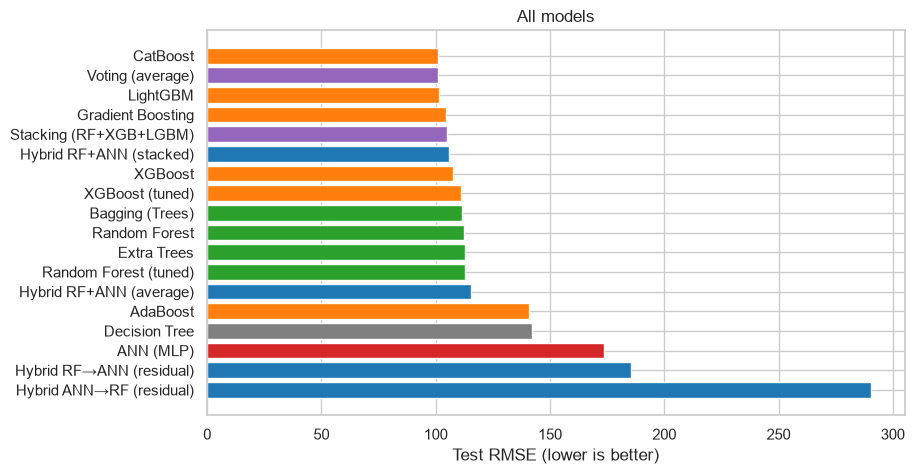

Best overall: CatBoost (RMSE 100.9, R2 0.972)
Bagging best: Bagging (Trees) (111.6) | Boosting best: CatBoost (100.9) -> boosting wins
RF vs XGBoost: XGBoost is better by 1.5% RMSE (RF R2 0.965, 13.9s | XGB R2 0.966, 8.43s)
Stacking 104.9 vs best single model 100.9 (CatBoost)
Best hybrid: Hybrid RF+ANN (stacked) (105.6) vs ANN alone 173.6 and tuned RF 112.7


In [38]:
final = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(final.round(3))
colors = {"Baseline": "grey", "Bagging": "tab:green", "Boosting": "tab:orange", "Stacking": "tab:purple", "ANN": "tab:red", "Hybrid": "tab:blue"}
f = final.sort_values("RMSE", ascending=False)
plt.figure(figsize=(9, 5)); plt.barh(f.Model, f.RMSE, color=[colors.get(x, "grey") for x in f.Family])
plt.xlabel("Test RMSE (lower is better)"); plt.title("All models"); plt.show()

g = lambda n: final[final.Model == n].iloc[0]
best, rf, xg = final.iloc[0], g("Random Forest (tuned)"), g("XGBoost (tuned)")
bag, boo = final[final.Family == "Bagging"].iloc[0], final[final.Family == "Boosting"].iloc[0]
hyb_b = final[final.Family == "Hybrid"].iloc[0]
single = final[final.Family.isin(["Baseline", "Bagging", "Boosting"])].iloc[0]
winner = "XGBoost" if xg.RMSE < rf.RMSE else "Random Forest"
gap = abs(xg.RMSE - rf.RMSE) / max(xg.RMSE, rf.RMSE) * 100
print(f"Best overall: {best.Model} (RMSE {best.RMSE:.1f}, R2 {best.R2:.3f})")
print(f"Bagging best: {bag.Model} ({bag.RMSE:.1f}) | Boosting best: {boo.Model} ({boo.RMSE:.1f}) -> {'boosting' if boo.RMSE < bag.RMSE else 'bagging'} wins")
print(f"RF vs XGBoost: {winner} is better by {gap:.1f}% RMSE (RF R2 {rf.R2:.3f}, {rf.Train_sec}s | XGB R2 {xg.R2:.3f}, {xg.Train_sec}s)")
print(f"Stacking {g('Stacking (RF+XGB+LGBM)').RMSE:.1f} vs best single model {single.RMSE:.1f} ({single.Model})")
print(f"Best hybrid: {hyb_b.Model} ({hyb_b.RMSE:.1f}) vs ANN alone {g('ANN (MLP)').RMSE:.1f} and tuned RF {rf.RMSE:.1f}")

## 11. Dashboard
The Streamlit dashboard (`app.py`) is self-contained: it reads `colombo_tea_auction.csv`, trains the same model families and shows the results. Run it with `streamlit run app.py`.

## 12. Conclusions & innovation idea
**Findings** *(use the numbers printed in section 10; write them in your own words)*:
1. Boosting vs bagging vs stacking: which family won, and by how much over the single decision tree?
2. RF vs XGBoost: which was better, and why (sequential error correction vs averaging independent trees)?
3. Hybrids: did RF+ARIMA beat ARIMA, and did RF+ANN beat each model alone? A hybrid only helps if the second model learns what the first one missed.
4. Most important features (permutation importance): usually the previous sale price (lag1), catalogue/category and the exchange rate.

**Innovation idea: "Fair-Price Meter and Best Time to Sell" advisor.** The dashboard turns the model and seasonality into practical advice for tea exporters and small growers: a fair-price range from several ensemble models, a flag when an asking price is more than 20% above the estimate, and the best months to sell each tea category.

**Limitations:** *(few years of data, sale dates approximated, no auction-quality or global-demand data.)*



13. Save the best model 


In [39]:
import joblib, os, json

os.makedirs("models", exist_ok=True)

cand = final[final.Model.isin(fitted.keys()) & ~final.Model.str.contains("residual")]
best_name = cand.iloc[0].Model
best_model = fitted[best_name]

joblib.dump(pre, "models/preprocessor.joblib", compress=3)
joblib.dump(best_model, "models/best_model.joblib", compress=3)

json.dump({"best_model": best_name, "target": TARGET, "features": feat,
           "rmse": float(cand.iloc[0].RMSE), "r2": float(cand.iloc[0].R2),
           "test_starts": str(pd.Timestamp(cutoff).date())},
          open("models/model_info.json", "w"), indent=2)

for f in os.listdir("models"):
    print(f, round(os.path.getsize(f"models/{f}") / 1e6, 2), "MB")
print("Saved best model:", best_name)

best_model.joblib 0.14 MB
model_info.json 0.0 MB
preprocessor.joblib 0.0 MB
Saved best model: CatBoost
